# بخش 2: RNN ساده

In [60]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import time
from torch.utils.data import DataLoader, TensorDataset

from data_utils import (
    load_synthetic_data, split_train_test, normalize_data,
    create_sequences, get_dataloaders, get_train_test_sequences,
	get_dataloaders_no_normalize, get_train_test_sequences_no_normalize
)
from plotting import (
    plot_time_series, plot_all_features, plot_correlation_heatmap,
    plot_rnn_results, plot_seq_length_results, plot_num_layers_results,
    create_results_table, save_table, plot_training_stability, RESULT_DIR
)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [48]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(42)
np.random.seed(42)
data_path=None
train_ratio=0.8
batch_size = 64
epochs = 100
learning_rate = 0.05
seq_length=10
plot_start=0
plot_end=1000
target_series_name="01_target_series"
all_features_name="02_all_features"
correlation_heatmap_name="03_correlation_heatmap"

# Experiment parameters
hidden_sizes = [8, 16, 32, 64, 128, 256]
seq_lengths = [10, 20, 50, 100, 200]
num_layers_list = [1, 2, 3, 4]

# Fixed parameters for sensitivity experiments
default_hidden_size = 32
default_seq_length = 20
default_num_layers = 1


ﻳﮏ ﻣﻌﻤﺎﺭﯼ ﺑﺎﺯﮔﺸﺘﯽ ﺳﺎﺩﻩ ﺑﻪ ﺻﻮﺭﺕ ﺯیر ﭘﻴﺎﺩﻩ ﺳﺎﺯﯼ ﻛﻨﻴﺪ:

Input(5ﺑﻌﺪ) → RNN Cell → Linear → y^(t+1) 

ﺗﺎﺑﻊ ﻣﻴﺎﻧﮕﻴﻦ ﻣﺮبعاﺕ ﺧﻄﺎ (MSE) ﺭﻭﯼ ﭘﻴﺶ ﺑﻴﻨﯽﮔﺎﻡ ﺑﻌﺪ ﺭﺍ ﺑﻌﻨﻮﺍﻥ ﺗﺎﺑﻊ ﻫﺰینه ﺑﻜﺎﺭ ﺑﮕﻴﺮید.


2-1 ﺁﺯﻣﺎﻳﺶ ۱: ﺣﺴﺎﺳﻴﺖ ﺑﻪ ﺍﻧﺪﺍﺯﻩ ﺑﺮﺩﺍﺭ حالت

ﺍﻧﺪﺍﺯﻩ ﻻﻳﻪ ﺑﺎﺯﮔﺸﺘﯽ (hidden size) ﺭﺍ ﺑﻪ ﺗﺮﺗﻴﺐ 256 ,128 ,64 ,32 ,16 ,8 ﻗﺮﺍﺭ ﺩﻫﻴﺪ (ﺳﺎﻳﺮ ﻫﺎﻳﭙﺮ پاﺭﺍﻣﺘﺮ ﻫﺎ ﺛﺎبت: ﺗﻌﺪﺍﺩ ﻻﻳﻪ ﻫﺎﯼ ﺑﺎﺯﮔﺸﺘﯽ=۱، ﻃﻮﻝ ﭘﻨﺠﺮﻩ ﻭﺭﻭﺩﯼ N = 20). 

In [49]:
# CELL 2: Define Simple RNN Model

class SimpleRNN(nn.Module):
    def __init__(self, input_size=5, hidden_size=32, num_layers=1, output_size=1):
        super(SimpleRNN, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        
        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            nonlinearity='tanh'
        )
        self.fc = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        # x shape: (batch, seq_len, input_size)
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_size).to(x.device)
        out, _ = self.rnn(x, h0)
        # Take output from last time step
        out = out[:, -1, :]
        out = self.fc(out)
        return out.squeeze(-1)

In [50]:
# CELL 3: Training Function

def train_model(model, train_loader, test_loader, epochs=50, lr=0.001):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_losses = []
    test_losses = []
    
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        avg_train_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # Evaluation
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                test_loss += loss.item()
        
        avg_test_loss = test_loss / len(test_loader)
        test_losses.append(avg_test_loss)
        
        if (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.6f} | Test Loss: {avg_test_loss:.6f}")
    
    training_time = time.time() - start_time
    return train_losses, test_losses, training_time


def get_model_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

In [51]:
# CELL 4: Get base data loaders (using default seq_length for consistency)

train_loader_base, test_loader_base, stats = get_dataloaders(
    seq_length=default_seq_length,
    batch_size=batch_size,
    data_path=data_path
)

print(f"Base train loader: {len(train_loader_base.dataset)} samples")
print(f"Base test loader: {len(test_loader_base.dataset)} samples")

Base train loader: 39964 samples
Base test loader: 9976 samples


In [52]:
X_train, y_train, X_test, y_test, stats = get_train_test_sequences(seq_length=20)
print(f"X_train mean: {X_train.mean():.6f}, std: {X_train.std():.6f}")
print(f"y_train mean: {y_train.mean():.6f}, std: {y_train.std():.6f}")
print(f"X_train min: {X_train.min():.6f}, max: {X_train.max():.6f}")

X_train mean: -0.000080, std: 1.000002
y_train mean: 0.000057, std: 1.000063
X_train min: -2.030625, max: 2.020750


In [53]:
X_train, y_train, X_test, y_test = get_train_test_sequences_no_normalize(seq_length=20)
print(f"X_train mean: {X_train.mean():.6f}, std: {X_train.std():.6f}")
print(f"y_train mean: {y_train.mean():.6f}, std: {y_train.std():.6f}")
print(f"X_train min: {X_train.min():.6f}, max: {X_train.max():.6f}")

X_train mean: -0.003827, std: 1.096829
y_train mean: -1.643464, std: 3.187918
X_train min: -2.880000, max: 2.870000


In [54]:
data = load_synthetic_data(data_path)
y = data['y']
print(f"Variance of y: {np.var(y):.6f}")
print(f"Std of y: {np.std(y):.6f}")

Variance of y: 10.501161
Std of y: 3.240549


In [55]:
# CELL 5: Experiment 1 - Sensitivity to Hidden Size

print("\n" + "="*60)
print("EXPERIMENT 1: Sensitivity to Hidden Size")
print("="*60)

results_hidden = []

for hidden_size in hidden_sizes:
    print(f"\n--- Training with hidden_size = {hidden_size} ---")
    
    # Create fresh dataloaders to avoid sequence length mismatch
    train_loader, test_loader, _ = get_dataloaders(
        seq_length=default_seq_length,
        batch_size=batch_size,
        data_path=data_path
    )
    
    model = SimpleRNN(
        input_size=5,
        hidden_size=hidden_size,
        num_layers=default_num_layers,
        output_size=1
    )
    
    num_params = get_model_params(model)
    print(f"Number of parameters: {num_params:,}")
    
    train_losses, test_losses, training_time = train_model(
        model, train_loader, test_loader, 
        epochs=epochs, lr=learning_rate
    )
    
    final_mse = test_losses[-1]
    results_hidden.append({
        'hidden_size': hidden_size,
        'num_params': num_params,
        'final_mse': final_mse,
        'training_time': training_time
    })
    
    print(f"Final MSE: {final_mse:.6f} | Time: {training_time:.2f}s")



EXPERIMENT 1: Sensitivity to Hidden Size

--- Training with hidden_size = 8 ---
Number of parameters: 129
Epoch 10/100 | Train Loss: 0.514627 | Test Loss: 0.537588
Epoch 20/100 | Train Loss: 0.547307 | Test Loss: 0.511727
Epoch 30/100 | Train Loss: 0.537707 | Test Loss: 0.554328
Epoch 40/100 | Train Loss: 0.573061 | Test Loss: 0.577711
Epoch 50/100 | Train Loss: 0.575650 | Test Loss: 0.620548
Epoch 60/100 | Train Loss: 0.517303 | Test Loss: 0.531934
Epoch 70/100 | Train Loss: 0.518657 | Test Loss: 0.593843
Epoch 80/100 | Train Loss: 0.575037 | Test Loss: 0.595935
Epoch 90/100 | Train Loss: 0.505255 | Test Loss: 0.515023
Epoch 100/100 | Train Loss: 0.551216 | Test Loss: 0.520971
Final MSE: 0.520971 | Time: 134.95s

--- Training with hidden_size = 16 ---
Number of parameters: 385
Epoch 10/100 | Train Loss: 0.492836 | Test Loss: 0.537892
Epoch 20/100 | Train Loss: 0.454105 | Test Loss: 0.445398
Epoch 30/100 | Train Loss: 0.490396 | Test Loss: 0.486721
Epoch 40/100 | Train Loss: 0.446167 

In [56]:

# Create and save results table
columns = ['Hidden Size', 'Parameters', 'Test MSE', 'Training Time (s)']
table_data = [[r['hidden_size'], r['num_params'], r['final_mse'], r['training_time']] 
              for r in results_hidden]
df_hidden = create_results_table(table_data, columns, 'rnn_hidden_size_results')



 Hidden Size  Parameters  Test MSE  Training Time (s)
           8         129  0.520971         134.947105
          16         385  0.491162         134.340883
          32        1281  0.502108         132.412456
          64        4609  0.533622         132.681431
         128       17409  1.269393         133.884069
         256       67585  1.002243         136.480764


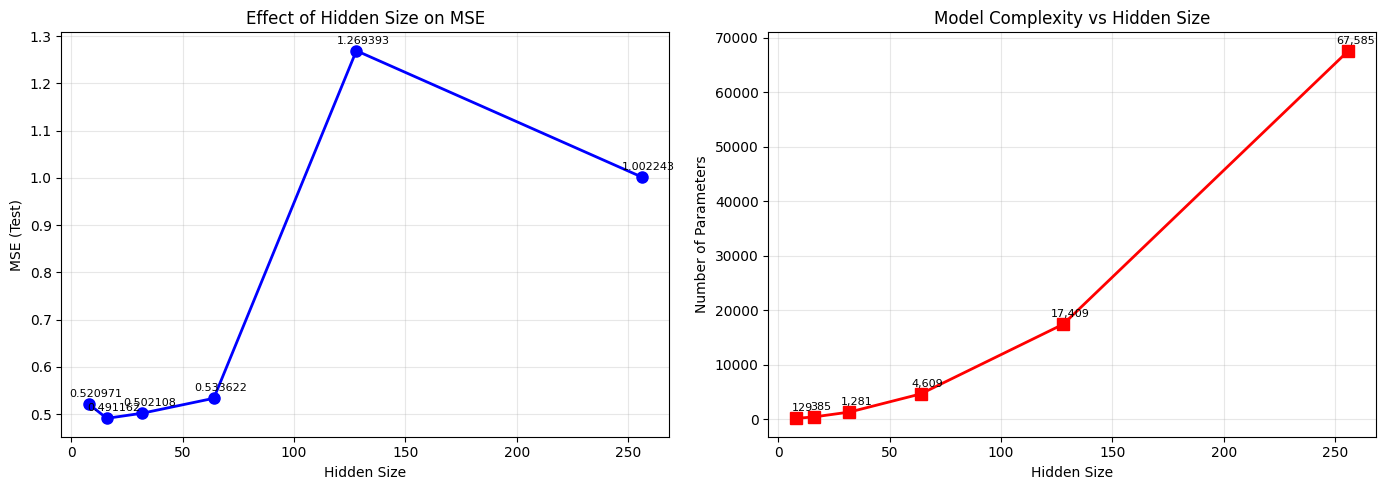

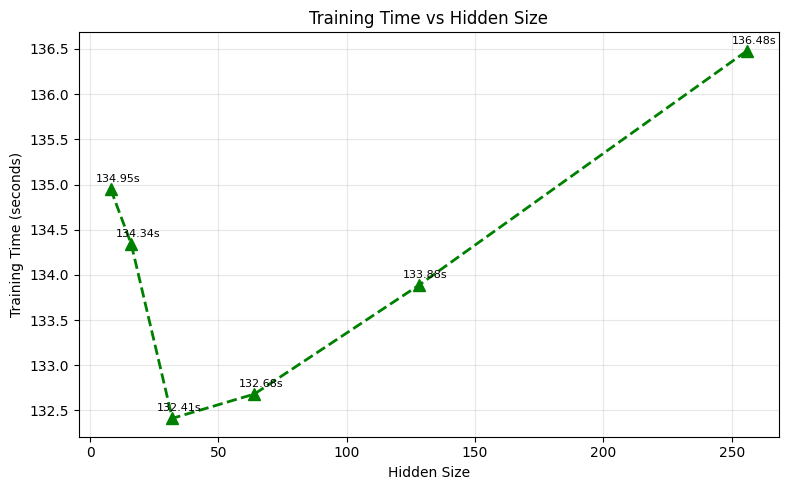

In [57]:

# Plot results
plot_rnn_results(
    [r['hidden_size'] for r in results_hidden],
    [r['final_mse'] for r in results_hidden],
    [r['num_params'] for r in results_hidden],
    [r['training_time'] for r in results_hidden],
    save_name_prefix="rnn_hidden_size"
)

الف) ﺍﻓﺰﺍﻳﺶ ﺍﻧﺪﺍﺯﻩ ﻧﻬﺎﻥ ﭼﻪ ﺍﺛﺮﯼ ﺑﺮ ﺧﻄﺎ ﻭ ﺯﻣﺎﻥ ﺁﻣﻮﺯﺵ ﺩﺍﺭﺩ؟ ﺁﻳﺎ ﻫﻤﻴﺸﻪ ﺍﻓﺰﺍﻳﺶ ﺍﻧﺪﺍﺯﻩ ﻧﻬﺎﻥ ﻣﻔﻴﺪ ﺍﺳﺖ؟

ب) رابطه بین تعداد پارامتر ها و تعمیم‌ پذیری مدل را توضیح دهید.

# جواب به صورت تشریحی

2-2 آزمایش 2: حساسیت به طول پنجره ورودی

طول پنجره N را 10, 20, 50, 100, 200 در نظر بگیرید (اندازه نهان ثابت 32). مقدار MSE را برای هر حالت گزارش کنید.

In [59]:
# CELL 6: Experiment 2 - Sensitivity to Sequence Length (Window Size)

print("\n" + "="*60)
print("EXPERIMENT 2: Sensitivity to Sequence Length")
print("="*60)

results_seq = []

for seq_len in seq_lengths:
    print(f"\n--- Training with seq_length = {seq_len} ---")
    
    train_loader, test_loader, _ = get_dataloaders(
        seq_length=seq_len,
        batch_size=batch_size,
        data_path=data_path
    )
    
    model = SimpleRNN(
        input_size=5,
        hidden_size=default_hidden_size,
        num_layers=default_num_layers,
        output_size=1
    )
    
    num_params = get_model_params(model)
    print(f"Number of parameters: {num_params:,}")
    
    train_losses, test_losses, training_time = train_model(
        model, train_loader, test_loader,
        epochs=epochs, lr=learning_rate
    )
    
    final_mse = test_losses[-1]
    results_seq.append({
        'seq_length': seq_len,
        'final_mse': final_mse,
        'training_time': training_time
    })
    
    print(f"Final MSE: {final_mse:.6f} | Time: {training_time:.2f}s")



EXPERIMENT 2: Sensitivity to Sequence Length

--- Training with seq_length = 10 ---
Number of parameters: 1,281
Epoch 10/100 | Train Loss: 0.493360 | Test Loss: 0.457260
Epoch 20/100 | Train Loss: 0.482721 | Test Loss: 0.518017
Epoch 30/100 | Train Loss: 0.529993 | Test Loss: 0.477004
Epoch 40/100 | Train Loss: 0.612617 | Test Loss: 0.732196
Epoch 50/100 | Train Loss: 0.562676 | Test Loss: 0.550624
Epoch 60/100 | Train Loss: 0.692386 | Test Loss: 0.626047
Epoch 70/100 | Train Loss: 0.502568 | Test Loss: 0.590830
Epoch 80/100 | Train Loss: 0.507930 | Test Loss: 0.480945
Epoch 90/100 | Train Loss: 0.584312 | Test Loss: 0.741663
Epoch 100/100 | Train Loss: 0.554210 | Test Loss: 0.662817
Final MSE: 0.662817 | Time: 136.18s

--- Training with seq_length = 20 ---
Number of parameters: 1,281
Epoch 10/100 | Train Loss: 0.477195 | Test Loss: 0.451344
Epoch 20/100 | Train Loss: 0.566806 | Test Loss: 0.682003
Epoch 30/100 | Train Loss: 0.633228 | Test Loss: 0.617389
Epoch 40/100 | Train Loss: 0.

In [61]:

# Create and save results table
columns_seq = ['Sequence Length', 'Test MSE', 'Training Time (s)']
table_data_seq = [[r['seq_length'], r['final_mse'], r['training_time']] for r in results_seq]
df_seq = create_results_table(table_data_seq, columns_seq, 'rnn_seq_length_results')



 Sequence Length  Test MSE  Training Time (s)
              10  0.662817         136.177977
              20  0.726647         136.624822
              50  0.581687         139.270303
             100  0.450449         142.311459
             200  0.906843         142.935310


الف) طول پنجره بزرگتر چگونه برکیفیت پیش بینی تأثیر می گذارد؟

ب) در چه طول پنجره ای عملکرد به اشباع می رسد؟ دلیل آن را با توجه به وابستگی های زمانی موجود در داده تحلیل کنید.

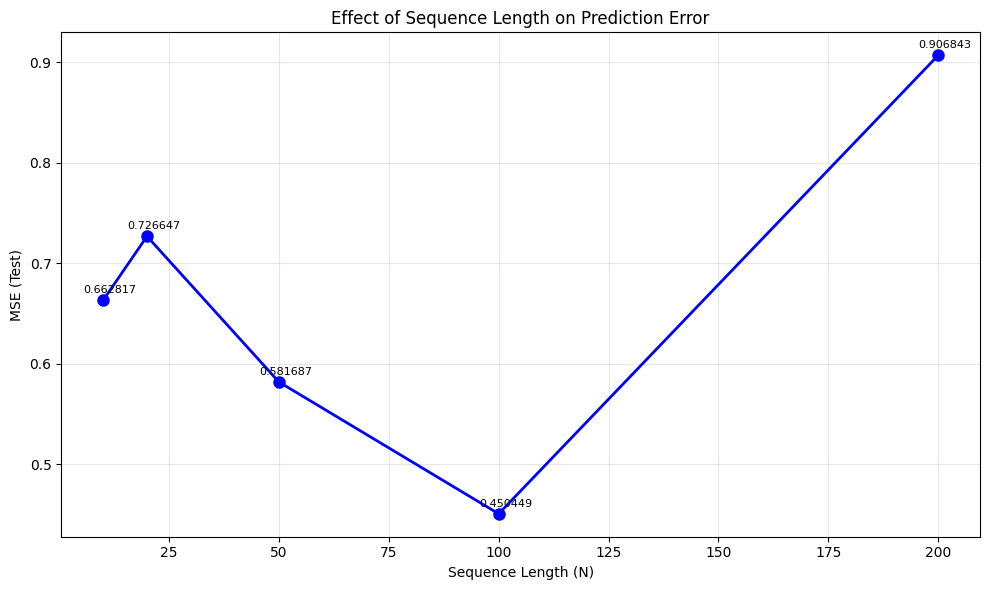

In [62]:

# Plot results
plot_seq_length_results(
    [r['seq_length'] for r in results_seq],
    [r['final_mse'] for r in results_seq],
    save_name_prefix="rnn_seq_length"
)

2-3 آزمایش 3: تعداد لایه های بازگشتی

تعداد لایه های RNN را 1, 2, 3, 4 تغییر دهید (سایر پارامترها ثابت: اندازه نهان 32، طول پنجره 20). برای هر تعداد لایه، خطا و پایداری آموزش را گزارش کنید.

آیا افزایش تعداد لایه ها همیشه باعث بهبود پیش بینی می شود؟


In [63]:
# CELL 3: Training Function with Stability Tracking

def train_model(model, train_loader, test_loader, epochs=50, lr=0.001, verbose=True):
    model = model.to(device)
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    train_losses = []
    test_losses = []
    
    # For stability tracking
    loss_changes = []  # Track how much loss changes between epochs
    rolling_stability = []  # Rolling standard deviation of last 10 losses
    
    start_time = time.time()
    
    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        
        avg_train_loss = epoch_loss / len(train_loader)
        train_losses.append(avg_train_loss)
        
        # Evaluation
        model.eval()
        test_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in test_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)
                test_loss += loss.item()
        
        avg_test_loss = test_loss / len(test_loader)
        test_losses.append(avg_test_loss)
        
        # Track loss change (stability metric)
        if epoch > 0:
            change = abs(test_losses[-1] - test_losses[-2])
            loss_changes.append(change)
        
        # Rolling stability (std of last 10 test losses)
        if epoch >= 9:
            rolling_std = np.std(test_losses[-10:])
            rolling_stability.append(rolling_std)
        
        if verbose and (epoch + 1) % 10 == 0:
            stability_info = f" | Change: {change:.6f}" if epoch > 0 else ""
            print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.6f} | Test Loss: {avg_test_loss:.6f}{stability_info}")
    
    training_time = time.time() - start_time
    
    # Calculate stability metrics
    stability_metrics = {
        'final_loss_std': np.std(test_losses[-20:]) if len(test_losses) >= 20 else np.std(test_losses),
        'max_loss_change': max(loss_changes) if loss_changes else 0,
        'avg_loss_change': np.mean(loss_changes) if loss_changes else 0,
        'loss_range': max(test_losses) - min(test_losses),
        'has_divergence': max(test_losses) > 5 * min(test_losses[10:]) if len(test_losses) > 10 else False,
        'convergence_epoch': get_convergence_epoch(test_losses)
    }
    
    return train_losses, test_losses, training_time, stability_metrics


def get_model_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def get_convergence_epoch(losses, threshold=0.01):
    """Find first epoch where loss stabilizes (change < threshold for 5 consecutive epochs)"""
    for i in range(5, len(losses)):
        recent_changes = [abs(losses[j] - losses[j-1]) for j in range(i-4, i+1)]
        if max(recent_changes) < threshold:
            return i - 4
    return len(losses)

In [64]:
all_train_losses = []
all_test_losses = []
config_labels = [f'{n} layers' for n in num_layers_list]
results_layers = []

for num_layers in num_layers_list:
    print(f"\n--- Training with num_layers = {num_layers} ---")
    
    train_loader, test_loader, _ = get_dataloaders(
        seq_length=default_seq_length,
        batch_size=batch_size,
        data_path=data_path
    )
    
    model = SimpleRNN(
        input_size=5,
        hidden_size=default_hidden_size,
        num_layers=num_layers,
        output_size=1
    )
    
    num_params = get_model_params(model)
    print(f"Number of parameters: {num_params:,}")
    
    train_losses, test_losses, train_time, stability = train_model(
        model, train_loader, test_loader, epochs=100, lr=0.05, verbose=True
    )
    
    all_train_losses.append(train_losses)
    all_test_losses.append(test_losses)
    
    results_layers.append({
        'num_layers': num_layers,
        'params': num_params,
        'final_mse': test_losses[-1],
        'best_mse': min(test_losses),
        'loss_std': stability['final_loss_std'],
        'convergence_epoch': stability['convergence_epoch'],
        'has_divergence': stability['has_divergence'],
        'train_time': train_time
    })
    
    print(f"Final MSE: {test_losses[-1]:.6f} | Best MSE: {min(test_losses):.6f}")
    print(f"Stability - Loss Std: {stability['final_loss_std']:.6f} | Divergence: {stability['has_divergence']}")



--- Training with num_layers = 1 ---
Number of parameters: 1,281
Epoch 10/100 | Train Loss: 0.484261 | Test Loss: 0.620579 | Change: 0.060026
Epoch 20/100 | Train Loss: 0.469135 | Test Loss: 0.522183 | Change: 0.090719
Epoch 30/100 | Train Loss: 0.473065 | Test Loss: 0.453401 | Change: 0.006715
Epoch 40/100 | Train Loss: 0.486054 | Test Loss: 0.541846 | Change: 0.090489
Epoch 50/100 | Train Loss: 0.483974 | Test Loss: 0.453432 | Change: 0.010896
Epoch 60/100 | Train Loss: 0.475060 | Test Loss: 0.435093 | Change: 0.084250
Epoch 70/100 | Train Loss: 0.474952 | Test Loss: 0.470650 | Change: 0.158048
Epoch 80/100 | Train Loss: 0.469155 | Test Loss: 0.444788 | Change: 0.002442
Epoch 90/100 | Train Loss: 0.470113 | Test Loss: 0.444645 | Change: 0.023424
Epoch 100/100 | Train Loss: 0.461740 | Test Loss: 0.439129 | Change: 0.007056
Final MSE: 0.439129 | Best MSE: 0.424297
Stability - Loss Std: 0.040448 | Divergence: False

--- Training with num_layers = 2 ---
Number of parameters: 3,393
Epoch

In [65]:

# Create and save results table
columns_layers = ['Number of Layers', 'Parameters', 'Test MSE', 'Training Time (s)']
table_data_layers = [[r['num_layers'], r['params'], r['final_mse'], r['train_time']] 
                     for r in results_layers]
df_layers = create_results_table(table_data_layers, columns_layers, 'rnn_num_layers_results')



 Number of Layers  Parameters  Test MSE  Training Time (s)
                1        1281  0.439129         135.513677
                2        3393  1.037394         151.357945
                3        5505  0.965754         164.794100
                4        7617  1.219855         184.906518


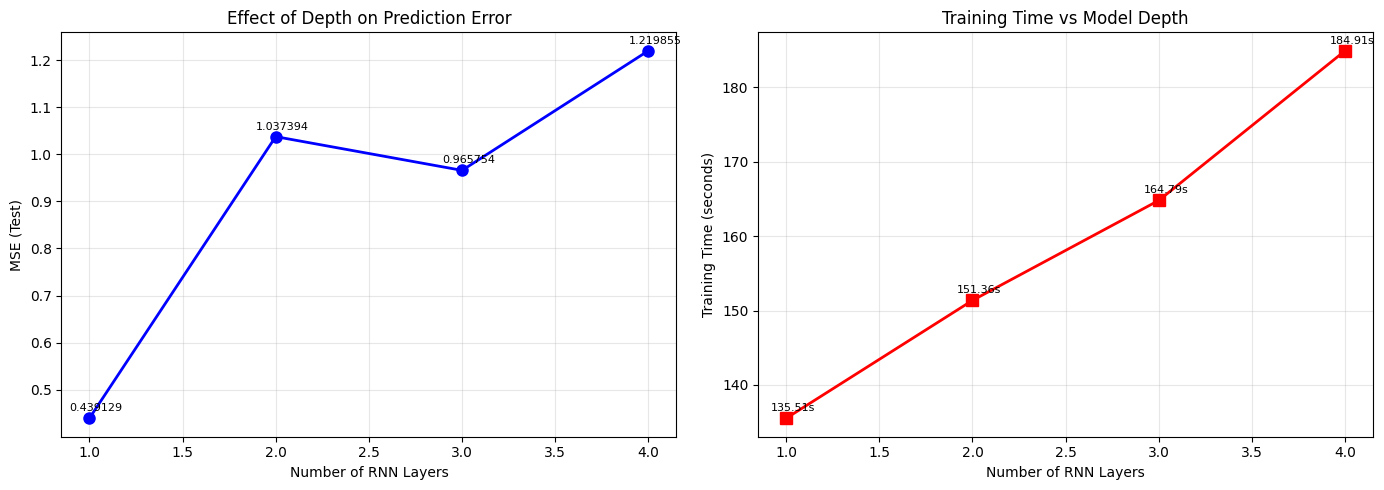

In [66]:

# Plot results
plot_num_layers_results(
    [r['num_layers'] for r in results_layers],
    [r['final_mse'] for r in results_layers],
    [r['train_time'] for r in results_layers],
    save_name_prefix="rnn_num_layers"
)

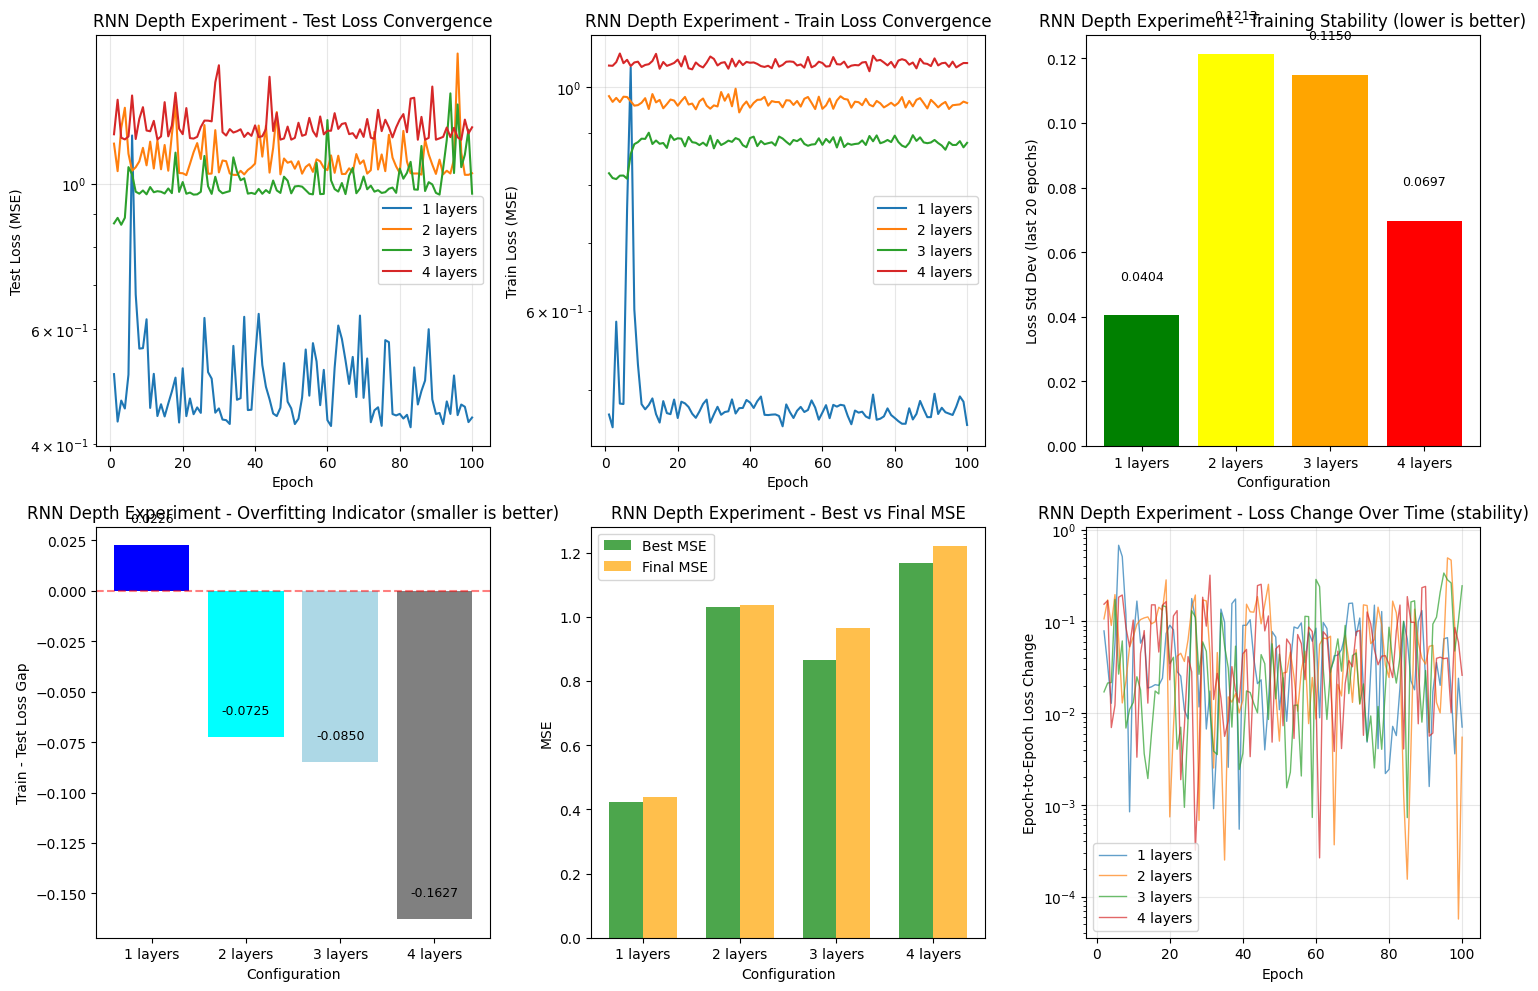

In [67]:
plot_training_stability(
    all_train_losses, 
    all_test_losses, 
    config_labels,
    title_prefix="RNN Depth Experiment",
    save_name="rnn_depth_stability"
)


In [69]:

# Print results table
print("\n" + "="*80)
print("RESULTS: Effect of Number of Layers on Stability")
print("="*80)
print(f"{'Layers':<8} {'Params':<12} {'Best MSE':<12} {'Final MSE':<12} {'Loss Std':<12} {'Converged Epoch':<12}")
print("-"*70)
for r in results_layers:
    print(f"{r['num_layers']:<8} {r['params']:<12,} {r['best_mse']:<12.6f} {r['final_mse']:<12.6f} {r['loss_std']:<12.6f} {r['convergence_epoch']:<12}")
print("="*80)


RESULTS: Effect of Number of Layers on Stability
Layers   Params       Best MSE     Final MSE    Loss Std     Converged Epoch
----------------------------------------------------------------------
1        1,281        0.424297     0.439129     0.040448     100         
2        3,393        1.030821     1.037394     0.121258     100         
3        5,505        0.865523     0.965754     0.114967     100         
4        7,617        1.167603     1.219855     0.069750     100         
